In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Setup is working")

In [ ]:
import akshare as ak

print("AKShare is working:", ak.__version__)

In [ ]:
import baostock as bs
import pandas as pd

# ============================================
# Cell 1: Define tickers and time window
# ============================================

tickers = {
    '600519': 'Kweichow_Moutai',
    '600547': 'Shandong_Gold',
    '601398': 'ICBC',
    '601318': 'Ping_An',
    '000333': 'Midea_Group',
    '300750': 'CATL',
    '600887': 'Yili',
    '600276': 'Hengrui_Medicine',
    '000002': 'Vanke',
    '002415': 'Hikvision'
}

start_date = '2019-01-01'
end_date = '2024-01-01'

print("Tickers defined:", len(tickers), "stocks")

In [ ]:
# ============================================
# Cell 2: Download daily data via baostock
# ============================================

lg = bs.login()

all_data = {}

for code, name in tickers.items():
    if code.startswith('6'):
        bs_code = 'sh.' + code
    else:
        bs_code = 'sz.' + code
    
    print(f"Downloading {name} ({bs_code})...")
    
    rs = bs.query_history_k_data_plus(
        bs_code,
        "date,close",
        start_date=start_date, end_date=end_date,
        frequency="d", adjustflag="2"
    )
    
    data_list = []
    while (rs.error_code == '0') & rs.next():
        data_list.append(rs.get_row_data())
    
    df = pd.DataFrame(data_list, columns=['Date', 'Close'])
    df['Date'] = pd.to_datetime(df['Date'])
    df['Close'] = df['Close'].astype(float)
    df = df.set_index('Date').sort_index()
    df = df.rename(columns={'Close': name})
    all_data[name] = df

bs.logout()

print("\nAll stocks downloaded.")
print("Number of stocks:", len(all_data))

In [20]:
# ============================================
# Cell 3: Download CSI 300 via baostock
# ============================================

lg = bs.login()

rs = bs.query_history_k_data_plus(
    "sh.000300",
    "date,close",
    start_date=start_date, end_date=end_date,
    frequency="d", adjustflag="3"
)

data_list = []
while (rs.error_code == '0') & rs.next():
    data_list.append(rs.get_row_data())

market = pd.DataFrame(data_list, columns=['Date', 'Market'])
market['Date'] = pd.to_datetime(market['Date'])
market['Market'] = market['Market'].astype(float)
market = market.set_index('Date').sort_index()

bs.logout()

print(market.head())
print("Market data shape:", market.shape)

login success!
logout success!
              Market
Date                
2019-01-02  2969.535
2019-01-03  2964.842
2019-01-04  3035.874
2019-01-07  3054.303
2019-01-08  3047.703
Market data shape: (1214, 1)


In [21]:
# ============================================
# Cell 4: Merge market + 10 stocks
# ============================================

prices = pd.concat([market] + list(all_data.values()), axis=1)
prices = prices.dropna()

print(prices.head())
print("\nFinal shape:", prices.shape)
print("\nColumns:", prices.columns.tolist())

              Market  Kweichow_Moutai  Shandong_Gold      ICBC    Ping_An  \
Date                                                                        
2019-01-02  2969.535       499.568487      14.949636  3.463569  39.372806   
2019-01-03  2964.842       492.078880      15.238826  3.463569  39.729573   
2019-01-04  3035.874       502.087264      15.214318  3.510194  40.378889   
2019-01-07  3054.303       504.998036      15.145697  3.490212  40.171964   
2019-01-08  3047.703       504.414213      14.307537  3.463569  39.815197   

            Midea_Group       CATL       Yili  Hengrui_Medicine      Vanke  \
Date                                                                         
2019-01-02    27.057356  37.643501  17.196031         29.813953  18.765515   
2019-01-03    26.879152  37.730379  17.058340         28.744545  18.898994   
2019-01-04    27.465741  39.329946  17.226629         30.590680  19.574238   
2019-01-07    27.465741  39.565026  17.417866         30.151660  19.66

In [ ]:
# ============================================
# Cell 5: Calculate returns and excess returns
# ============================================

# --- 1. Daily simple returns ---
returns = prices.pct_change().dropna()

# --- 2. Daily risk-free rate ---
# China 1-year government bond yield ~2.5% annualized
RF_ANNUAL = 0.025
TRADING_DAYS = 252
rf_daily = RF_ANNUAL / TRADING_DAYS

# --- 3. Excess returns ---
excess_returns = returns - rf_daily

print("Returns shape:", returns.shape)
print("\nFirst 5 rows of excess returns:")
print(excess_returns.head())

print("\nSummary statistics:")
print(excess_returns.describe())

In [26]:
# ============================================
# Cell 6: Run CAPM regression for each stock
# ============================================

import statsmodels.api as sm

# Market excess returns (X)
X = excess_returns['Market']

# Prepare results table
results = []

# List of stock columns (exclude Market)
stock_cols = [c for c in excess_returns.columns if c != 'Market']

for stock in stock_cols:
    # Make sure stock and market returns are aligned
    data = pd.concat(
        [excess_returns[stock], excess_returns['Market']],
        axis=1
    ).dropna()

    # Stock excess return (Y)
    y = data[stock]

    # Market excess return (X)
    X = data['Market']
    X = sm.add_constant(X)   # Add constant to get alpha

    model = sm.OLS(y, X).fit()
    
    results.append({
        'Stock': stock,
        'Alpha': model.params['const'],
        'Beta': model.params['Market'],
        'R_squared': model.rsquared,
        'p_alpha': model.pvalues['const'],
        'p_beta': model.pvalues['Market']
    })

# Create DataFrame
capm_results = pd.DataFrame(results)

print(capm_results.to_string(index=False))

           Stock     Alpha     Beta  R_squared  p_alpha        p_beta
 Kweichow_Moutai  0.000924 1.059477   0.461178 0.020953 8.276714e-165
   Shandong_Gold  0.000432 0.318848   0.031884 0.481292  3.779127e-10
            ICBC  0.000071 0.327224   0.175097 0.775509  1.314722e-52
         Ping_An -0.000147 0.998413   0.490936 0.679759 9.222428e-180
     Midea_Group  0.000462 1.083764   0.425036 0.293753 1.018679e-147
            CATL  0.001348 1.294367   0.293485 0.054733  1.856003e-93
            Yili  0.000236 0.989998   0.412295 0.567729 6.000850e-142
Hengrui_Medicine  0.000375 0.875903   0.252818 0.475213  1.040931e-78
           Vanke -0.000442 0.919171   0.274950 0.396177  1.237671e-86
       Hikvision  0.000404 1.194379   0.382437 0.445867 6.700371e-129


In [23]:
capm_results_sorted = capm_results.sort_values('Beta', ascending=False)

print("CAPM Results (sorted by Beta):")
print("=" * 80)
print(capm_results_sorted.to_string(index=False))

print("\nKey observations:")
print(f"Highest Beta: {capm_results_sorted.iloc[0]['Stock']} (Beta = {capm_results_sorted.iloc[0]['Beta']})")
print(f"Lowest Beta:  {capm_results_sorted.iloc[-1]['Stock']} (Beta = {capm_results_sorted.iloc[-1]['Beta']})")

CAPM Results (sorted by Beta):
           Stock     Alpha     Beta  R_squared  p_alpha  p_beta
            CATL  0.001348 1.294367   0.293485 0.054733     0.0
       Hikvision  0.000404 1.194379   0.382437 0.445867     0.0
     Midea_Group  0.000462 1.083764   0.425036 0.293753     0.0
 Kweichow_Moutai  0.000924 1.059477   0.461178 0.020953     0.0
         Ping_An -0.000147 0.998413   0.490936 0.679759     0.0
            Yili  0.000236 0.989998   0.412295 0.567729     0.0
           Vanke -0.000442 0.919171   0.274950 0.396177     0.0
Hengrui_Medicine  0.000375 0.875903   0.252818 0.475213     0.0
            ICBC  0.000071 0.327224   0.175097 0.775509     0.0
   Shandong_Gold  0.000432 0.318848   0.031884 0.481292     0.0

Key observations:
Highest Beta: CATL (Beta = 1.294367)
Lowest Beta:  Shandong_Gold (Beta = 0.318848)


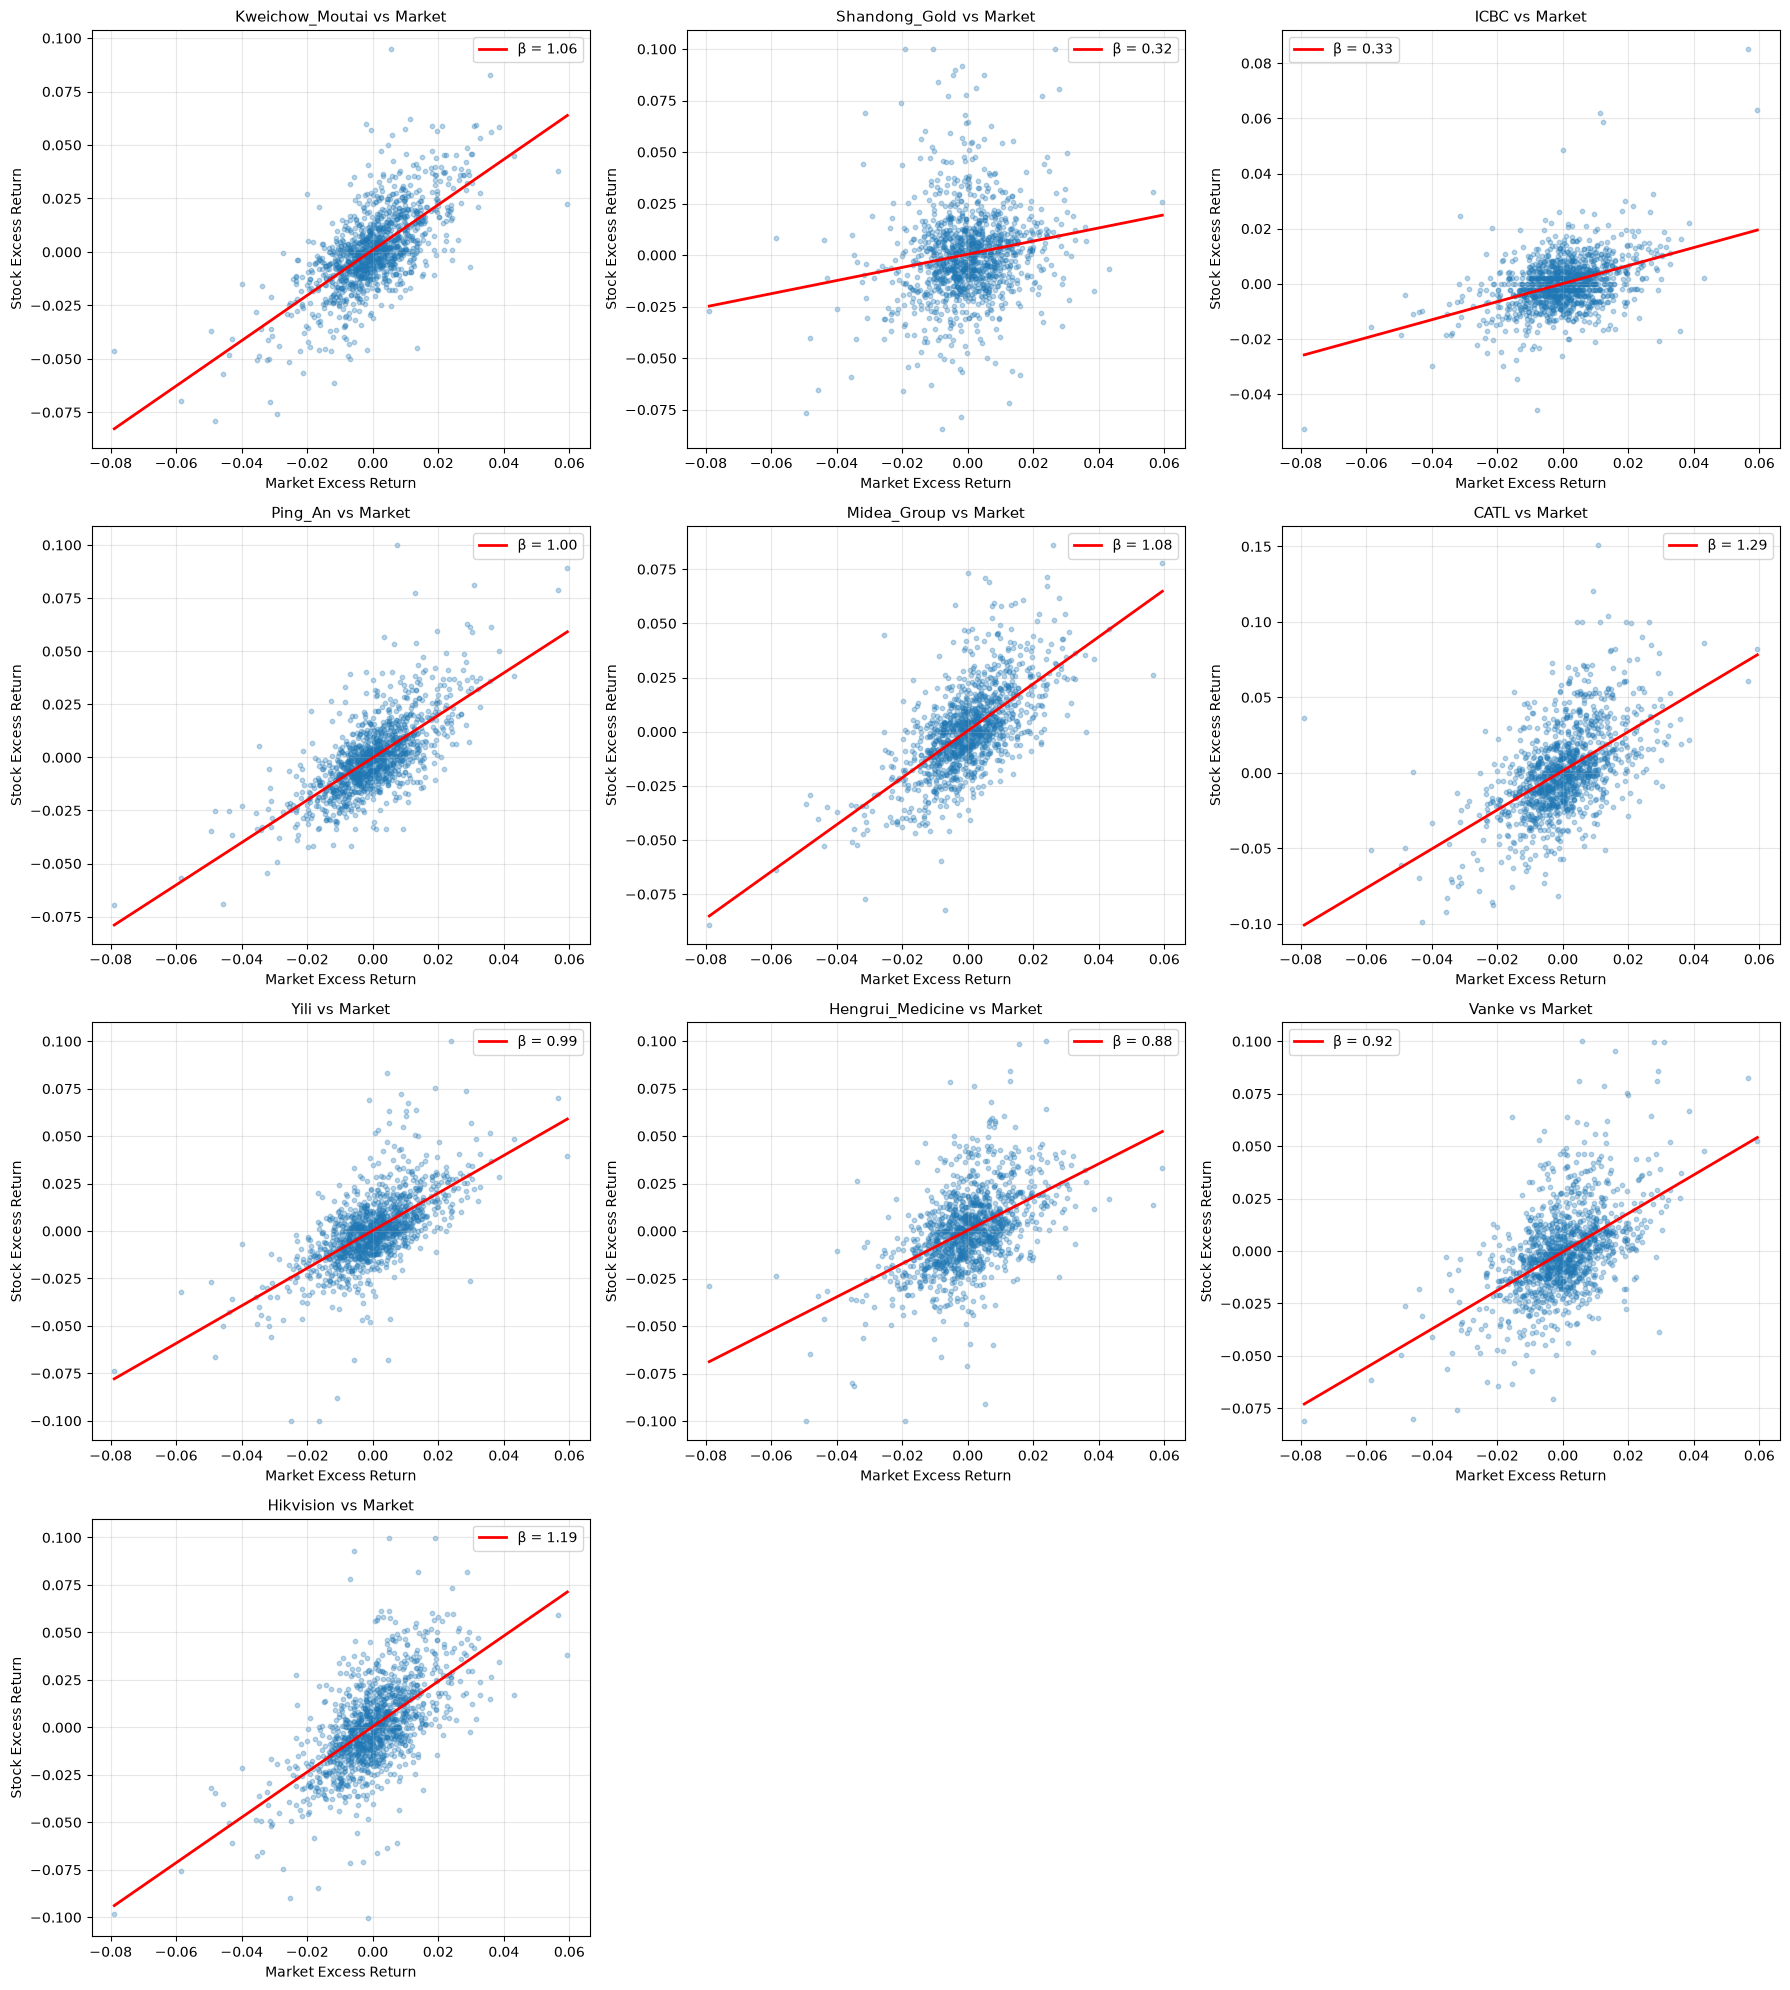

In [24]:
# ============================================
# Cell 8: Scatter plot + regression line (ALL 10 stocks)
# ============================================

import matplotlib.pyplot as plt
import numpy as np

x = excess_returns['Market']
all_stocks = [c for c in excess_returns.columns if c != 'Market']

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, stock in enumerate(all_stocks):
    y = excess_returns[stock]
    
    axes[i].scatter(x, y, alpha=0.3, s=10)
    
    beta, alpha = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = alpha + beta * x_line
    axes[i].plot(x_line, y_line, color='red', linewidth=2,
                 label=f'β = {beta:.2f}')
    
    axes[i].set_title(f'{stock} vs Market', fontsize=11)
    axes[i].set_xlabel('Market Excess Return')
    axes[i].set_ylabel('Stock Excess Return')
    axes[i].legend()
    axes[i].grid(alpha=0.3)

# Hide unused subplots (10 stocks, 12 slots)
for j in range(len(all_stocks), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

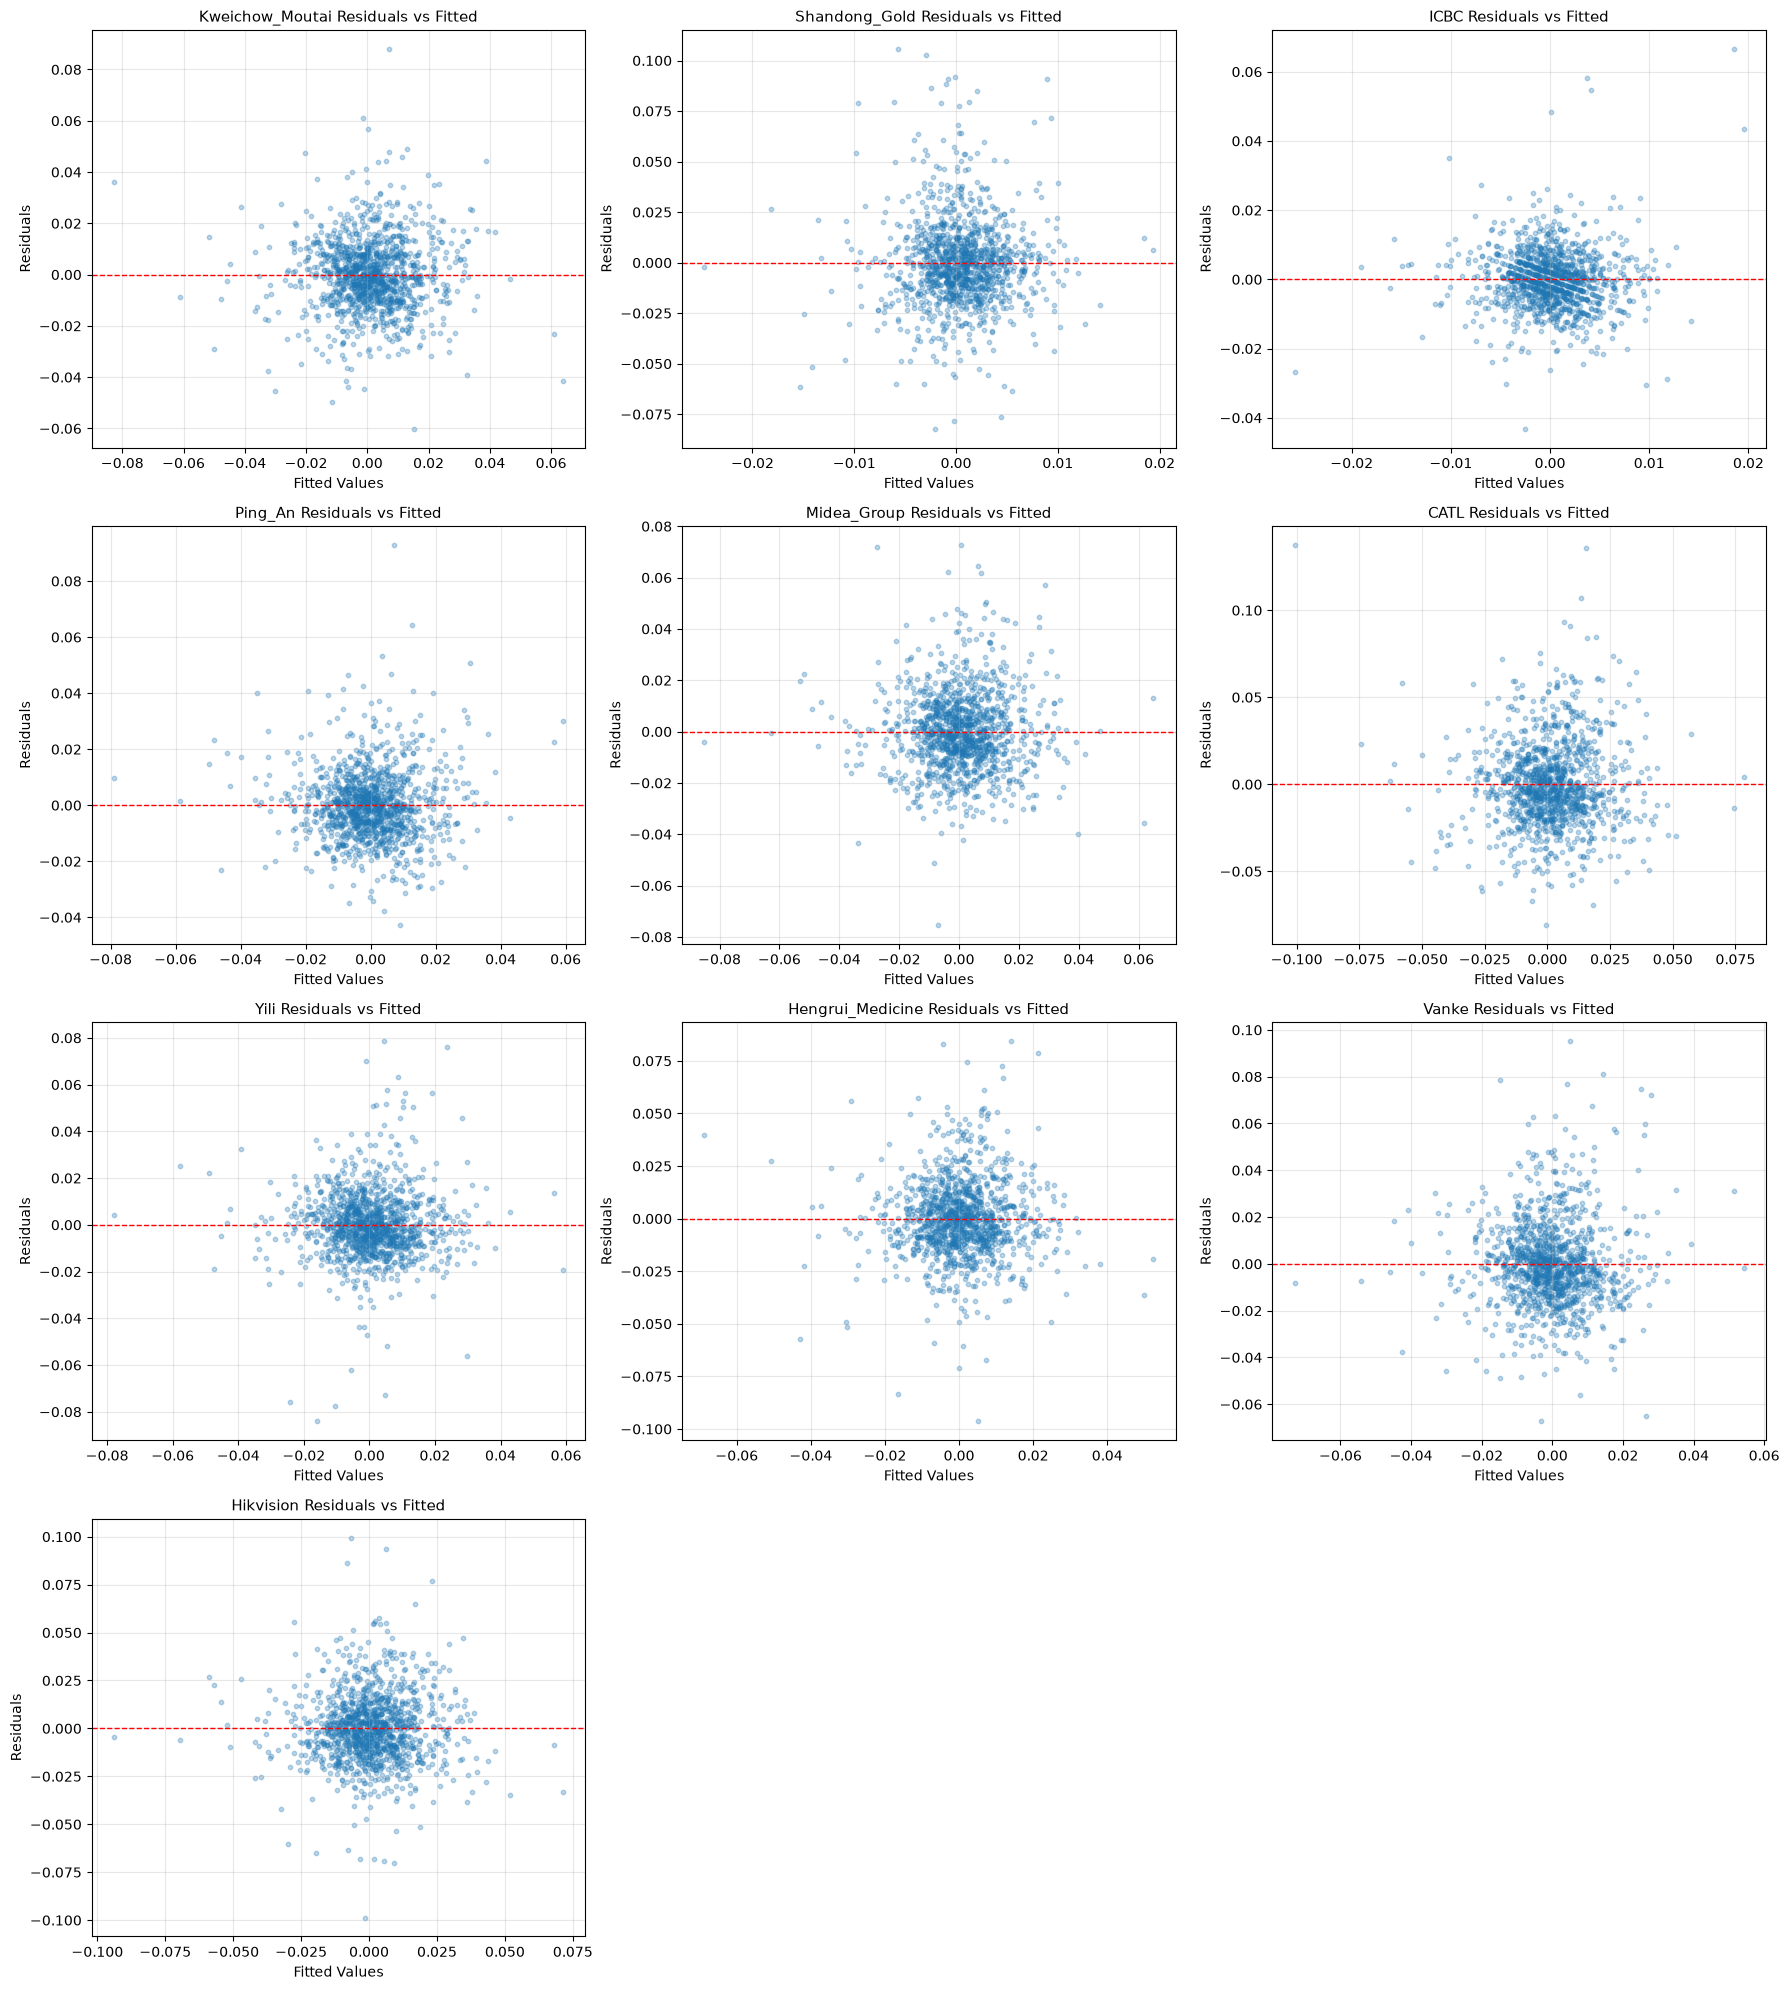

In [25]:
# ============================================
# Cell 9: Residual plots (ALL 10 stocks)
# ============================================

import statsmodels.api as sm

X = sm.add_constant(excess_returns['Market'])

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, stock in enumerate(all_stocks):
    y = excess_returns[stock]
    model = sm.OLS(y, X).fit()
    residuals = model.resid
    fitted = model.fittedvalues
    
    axes[i].scatter(fitted, residuals, alpha=0.3, s=10)
    axes[i].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i].set_title(f'{stock} Residuals vs Fitted', fontsize=11)
    axes[i].set_xlabel('Fitted Values')
    axes[i].set_ylabel('Residuals')
    axes[i].grid(alpha=0.3)

for j in range(len(all_stocks), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [19]:
# ============================================
# Cell 10: Normality test of residuals
# ============================================

from scipy import stats

print("Jarque-Bera Normality Test on Residuals")
print("=" * 70)
print(f"{'Stock':<22}{'JB Stat':>12}{'p-value':>12}{'Normal?':>12}")

for stock in all_stocks:
    y = excess_returns[stock]
    model = sm.OLS(y, X).fit()
    residuals = model.resid
    
    jb_stat, p_value = stats.jarque_bera(residuals)
    normal = "YES" if p_value > 0.05 else "NO"
    
    print(f"{stock:<22}{jb_stat:>12.2f}{p_value:>12.4f}{normal:>12}")

Jarque-Bera Normality Test on Residuals
Stock                      JB Stat     p-value     Normal?
Kweichow_Moutai             368.93      0.0000          NO
Shandong_Gold               714.04      0.0000          NO
ICBC                       3185.44      0.0000          NO
Ping_An                    1097.99      0.0000          NO
Midea_Group                 296.66      0.0000          NO
CATL                        381.83      0.0000          NO
Yili                       1835.39      0.0000          NO
Hengrui_Medicine            444.55      0.0000          NO
Vanke                       438.23      0.0000          NO
Hikvision                   512.15      0.0000          NO
